# ResNet18: Training from Scratch on HAM10000

## Objective
Train a ResNet18 convolutional neural network from random
initialization to classify the seven diagnostic categories
in the HAM10000 dermoscopic image dataset.

## Experimental setup
- Architecture: ResNet18
- Initialization: Random
- Dataset: HAM10000
- Number of classes: 7
- Input resolution: 224 × 224
- Evaluation: Group-aware train/validation/test split
- Primary evaluation metric: Macro-F1

## Important
All images belonging to the same lesion must remain in
the same partition to prevent data leakage.

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132


In [3]:
SEED = 20261117

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Available VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Available VRAM: 5.64 GB


In [4]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

METADATA_PATH = DATA_DIR / "HAM10000_metadata"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2"
]

print("Project root:", PROJECT_ROOT)
print("Metadata exists:", METADATA_PATH.exists())

for directory in IMAGE_DIRS:
    print(directory, "exists:", directory.exists())

Project root: /home/shishirdhar/Research/boundary-quantum-fidelity
Metadata exists: True
/home/shishirdhar/Research/boundary-quantum-fidelity/data/raw/HAM10000_images_part_1 exists: True
/home/shishirdhar/Research/boundary-quantum-fidelity/data/raw/HAM10000_images_part_2 exists: True


In [5]:
df = pd.read_csv(METADATA_PATH)

image_paths = {
    path.stem: path
    for directory in IMAGE_DIRS
    for path in directory.glob("*.jpg")
}

df["image_path"] = df["image_id"].map(image_paths)

assert df["image_path"].notna().all(), (
    "Some metadata entries do not have matching image files."
)

print("Images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())
print("\nDiagnostic categories:")
print(df["dx"].value_counts())

Images: 10015
Unique lesions: 7470

Diagnostic categories:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [6]:
# Count distinct diagnoses associated with each lesion

diagnoses_per_lesion = (
    df.groupby("lesion_id")["dx"].nunique()
)

inconsistent_lesions = diagnoses_per_lesion[
    diagnoses_per_lesion > 1
]

print("Lesions with multiple diagnoses:",
      len(inconsistent_lesions))

if len(inconsistent_lesions) > 0:
    print("\nInconsistent records:")
    display(
        df[df["lesion_id"].isin(inconsistent_lesions.index)]
        .sort_values("lesion_id")
    )
else:
    print("Every lesion has exactly one diagnosis.")

Lesions with multiple diagnoses: 0
Every lesion has exactly one diagnosis.


In [7]:
lesion_summary = (
    df.groupby("lesion_id")
    .agg(
        diagnosis=("dx", "first"),
        image_count=("image_id", "count")
    )
    .reset_index()
)

print("Total lesions:", len(lesion_summary))

print("\nLesions per diagnostic category:")
display(
    lesion_summary["diagnosis"]
    .value_counts()
    .sort_index()
    .to_frame("lesion_count")
)

print("\nImages per lesion:")
display(
    lesion_summary["image_count"]
    .value_counts()
    .sort_index()
    .to_frame("number_of_lesions")
)

Total lesions: 7470

Lesions per diagnostic category:


,lesion_count
diagnosis,
akiec,228
bcc,327
bkl,727
df,73
mel,614
nv,5403
vasc,98



Images per lesion:


,number_of_lesions
image_count,
1,5514
2,1423
3,490
4,34
5,5
6,4


In [8]:
from sklearn.model_selection import StratifiedKFold

lesion_summary = (
    df.groupby("lesion_id")
    .agg(
        diagnosis=("dx", "first"),
        image_count=("image_id", "count")
    )
    .reset_index()
)

print("Splitting units:", len(lesion_summary))
print("Unique diagnoses:", lesion_summary["diagnosis"].nunique())

Splitting units: 7470
Unique diagnoses: 7


In [9]:
# Stage 1: Separate the test set.

outer_splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=20261117
)

trainval_idx, test_idx = next(
    outer_splitter.split(
        lesion_summary,
        lesion_summary["diagnosis"]
    )
)

trainval_lesions = lesion_summary.iloc[trainval_idx].copy()
test_lesions = lesion_summary.iloc[test_idx].copy()


# Stage 2: Separate validation from training.

inner_splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=20261118
)

train_idx, val_idx = next(
    inner_splitter.split(
        trainval_lesions,
        trainval_lesions["diagnosis"]
    )
)

train_lesions = trainval_lesions.iloc[train_idx].copy()
val_lesions = trainval_lesions.iloc[val_idx].copy()


print("Lesion counts:")
print("Training:", len(train_lesions))
print("Validation:", len(val_lesions))
print("Testing:", len(test_lesions))

Lesion counts:
Training: 4780
Validation: 1196
Testing: 1494


In [10]:
train_ids = set(train_lesions["lesion_id"])
val_ids = set(val_lesions["lesion_id"])
test_ids = set(test_lesions["lesion_id"])

df["split"] = np.select(
    [
        df["lesion_id"].isin(train_ids),
        df["lesion_id"].isin(val_ids),
        df["lesion_id"].isin(test_ids)
    ],
    [
        "train",
        "validation",
        "test"
    ],
    default="unassigned"
)

assert (df["split"] != "unassigned").all()

# Verify that no lesion appears in multiple partitions.

split_counts = df.groupby("lesion_id")["split"].nunique()

assert split_counts.max() == 1

print("All images assigned.")
print("No lesion crosses partition boundaries.")

All images assigned.
No lesion crosses partition boundaries.


In [11]:
distribution = pd.crosstab(
    df["dx"],
    df["split"]
)

display(distribution)

print("\nImage counts:")
print(df["split"].value_counts())

print("\nLesion counts:")
print(
    df.groupby("split")["lesion_id"]
      .nunique()
)

split,test,train,validation
dx,,,
akiec,65,211,51
bcc,107,332,75
bkl,210,716,173
df,21,77,17
mel,226,708,179
nv,1348,4295,1062
vasc,29,90,23



Image counts:
split
train         6429
test          2006
validation    1580
Name: count, dtype: int64

Lesion counts:
split
test          1494
train         4780
validation    1196
Name: lesion_id, dtype: int64


In [12]:
print("Image proportions:")
display(
    df["split"].value_counts(normalize=True).mul(100).round(2)
)

print("Lesion proportions:")

lesion_proportions = (
    df.groupby("split")["lesion_id"]
      .nunique()
)

lesion_proportions = (
    lesion_proportions / lesion_proportions.sum() * 100
).round(2)

display(lesion_proportions)

Image proportions:


split
train         64.19
test          20.03
validation    15.78
Name: proportion, dtype: float64

Lesion proportions:


split
test          20.00
train         63.99
validation    16.01
Name: lesion_id, dtype: float64

In [13]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

manifest = df[
    ["image_id", "lesion_id", "dx", "image_path", "split"]
].copy()

manifest.to_csv(
    PROCESSED_DIR / "resnet18_exploratory_split.csv",
    index=False
)

print("Saved:", PROCESSED_DIR / "resnet18_exploratory_split.csv")

Saved: /home/shishirdhar/Research/boundary-quantum-fidelity/data/processed/resnet18_exploratory_split.csv


In [14]:
# Select one deterministic image per lesion.

evaluation_df = (
    df.sort_values("image_id")
      .drop_duplicates(subset="lesion_id", keep="first")
      .copy()
)

val_eval_df = evaluation_df[
    evaluation_df["split"] == "validation"
].copy()

test_eval_df = evaluation_df[
    evaluation_df["split"] == "test"
].copy()

print("Validation images:", len(val_eval_df))
print("Validation lesions:", val_eval_df["lesion_id"].nunique())

print("\nTest images:", len(test_eval_df))
print("Test lesions:", test_eval_df["lesion_id"].nunique())

assert len(val_eval_df) == val_eval_df["lesion_id"].nunique()
assert len(test_eval_df) == test_eval_df["lesion_id"].nunique()

Validation images: 1196
Validation lesions: 1196

Test images: 1494
Test lesions: 1494


In [15]:
evaluation_manifest = pd.concat([
    val_eval_df.assign(evaluation_split="validation"),
    test_eval_df.assign(evaluation_split="test")
])

evaluation_manifest[
    ["image_id", "lesion_id", "dx", "evaluation_split"]
].to_csv(
    PROCESSED_DIR / "resnet18_evaluation_manifest.csv",
    index=False
)

print("Evaluation manifest saved.")

Evaluation manifest saved.


In [16]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Common normalization for all experiments.
# These are ImageNet channel statistics, not pretrained weights.

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.85, 1.0),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        256,
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

In [17]:
classes = sorted(df["dx"].unique())

class_to_idx = {
    class_name: index
    for index, class_name in enumerate(classes)
}

idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

NUM_CLASSES = len(classes)

print("Class mapping:")
print(class_to_idx)

print("\nNumber of classes:", NUM_CLASSES)

Class mapping:
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}

Number of classes: 7


In [18]:
from torch.utils.data import Dataset
from PIL import Image

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = class_to_idx[row["dx"]]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [19]:
train_dataset = HAM10000Dataset(
    dataframe=df[df["split"] == "train"],
    transform=train_transform
)

val_dataset = HAM10000Dataset(
    dataframe=val_eval_df,
    transform=eval_transform
)

test_dataset = HAM10000Dataset(
    dataframe=test_eval_df,
    transform=eval_transform
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Testing examples:", len(test_dataset))

Training examples: 6429
Validation examples: 1196
Testing examples: 1494


In [22]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 402
Validation batches: 75
Testing batches: 94


In [23]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("\nLabels in first batch:")
print([idx_to_class[int(label)] for label in labels])

print("\nPixel value range after normalization:")
print(images.min().item(), images.max().item())

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image data type: torch.float32
Label data type: torch.int64

Labels in first batch:
['nv', 'nv', 'nv', 'bcc', 'nv', 'nv', 'nv', 'mel', 'bkl', 'df', 'bkl', 'bcc', 'nv', 'akiec', 'mel', 'bcc']

Pixel value range after normalization:
-2.1179039478302 2.640000104904175


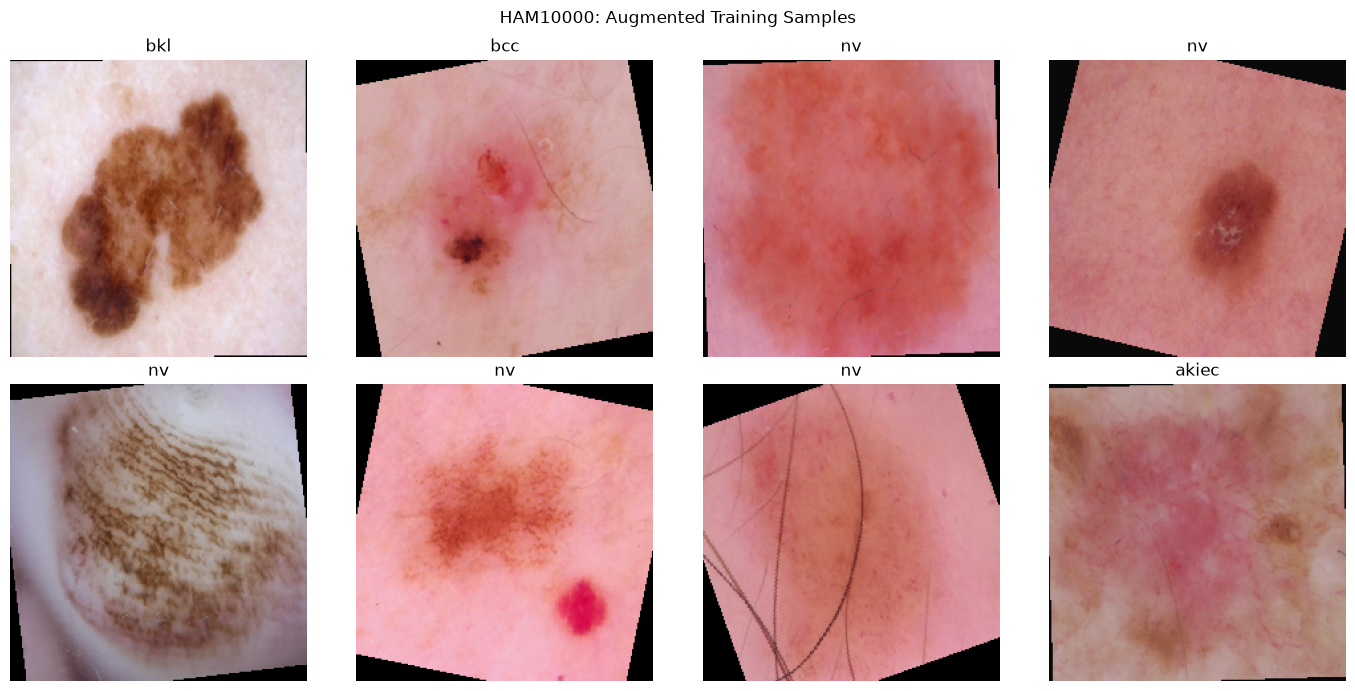

In [24]:
import matplotlib.pyplot as plt

# Get one batch
images, labels = next(iter(train_loader))

# Reverse ImageNet normalization for visualization
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1)

    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(idx_to_class[int(labels[i])])
    ax.axis("off")

plt.suptitle("HAM10000: Augmented Training Samples")
plt.tight_layout()
plt.show()

In [25]:
import torchvision.models as models

model = models.resnet18(weights=None)

# Replace the original 1000-class output layer.
model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [26]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 11,180,103
Trainable parameters: 11,180,103


In [27]:
model.eval()

images, labels = next(iter(train_loader))

images = images.to(DEVICE)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Output for first image:", outputs[0])

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 7])
Output for first image: tensor([ 0.7614, -1.0133,  0.0515,  0.7757,  0.4574, -0.4719, -0.3577],
       device='cuda:0')


In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)
PROJECT_ROOT = Path.cwd().parent

RESULTS_DIR = PROJECT_ROOT / "experiments" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EPOCHS = 30

BEST_MODEL_PATH = (
    RESULTS_DIR / "resnet18_from_scratch_best.pth"
)

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Checkpoint:", BEST_MODEL_PATH)

Device: cuda
Batch size: 16
Epochs: 30
Initial learning rate: 0.001
Checkpoint: /home/shishirdhar/Research/boundary-quantum-fidelity/experiments/results/resnet18_from_scratch_best.pth


In [32]:
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score
import time

# Mixed precision scaler
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)


def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    running_loss = 0.0
    total_samples = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return running_loss / total_samples


def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader, desc="Validation", leave=False
        ):

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / total_samples

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

In [33]:
history = []

best_val_f1 = -1.0

for epoch in range(EPOCHS):

    start_time = time.time()

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    # Validation
    val_loss, val_accuracy, val_f1 = validate(
        model,
        val_loader,
        criterion
    )

    # Update learning rate scheduler
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - start_time

    # Record metrics
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    })

    print(f"Train loss:       {train_loss:.4f}")
    print(f"Validation loss:  {val_loss:.4f}")
    print(f"Validation acc:   {val_accuracy:.4f}")
    print(f"Validation F1:    {val_f1:.4f}")
    print(f"Learning rate:    {current_lr:.6f}")
    print(f"Time:             {epoch_time:.1f}s")

    # Save best checkpoint based on validation macro-F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_f1": best_val_f1,
            "class_to_idx": class_to_idx,
            "seed": SEED
        }, BEST_MODEL_PATH)

        print("Best model checkpoint saved.")

    # Save training history after each epoch
    pd.DataFrame(history).to_csv(
        RESULTS_DIR / "resnet18_training_history.csv",
        index=False
    )

print("\nTraining completed.")
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print("Best checkpoint:", BEST_MODEL_PATH)


Epoch 1/30


Train loss:       1.0224
Validation loss:  0.7882
Validation acc:   0.7358
Validation F1:    0.1858
Learning rate:    0.001000
Time:             57.8s
Best model checkpoint saved.

Epoch 2/30


Train loss:       0.9473
Validation loss:  0.7679
Validation acc:   0.7283
Validation F1:    0.1450
Learning rate:    0.001000
Time:             55.1s

Epoch 3/30


Train loss:       0.8957
Validation loss:  0.6916
Validation acc:   0.7433
Validation F1:    0.2843
Learning rate:    0.001000
Time:             55.0s
Best model checkpoint saved.

Epoch 4/30


Train loss:       0.8709
Validation loss:  0.7052
Validation acc:   0.7592
Validation F1:    0.3520
Learning rate:    0.001000
Time:             56.6s
Best model checkpoint saved.

Epoch 5/30


Train loss:       0.8369
Validation loss:  0.7161
Validation acc:   0.7341
Validation F1:    0.2012
Learning rate:    0.001000
Time:             55.1s

Epoch 6/30


... (21 outputs left out)

Train loss:       0.5759
Validation loss:  0.5510
Validation acc:   0.8077
Validation F1:    0.5617
Learning rate:    0.000250
Time:             55.4s
Best model checkpoint saved.

Epoch 28/30


Train loss:       0.5719
Validation loss:  0.5386
Validation acc:   0.8110
Validation F1:    0.5649
Learning rate:    0.000250
Time:             56.7s
Best model checkpoint saved.

Epoch 29/30


Train loss:       0.5547
Validation loss:  0.5475
Validation acc:   0.7993
Validation F1:    0.5531
Learning rate:    0.000250
Time:             56.6s

Epoch 30/30


Train loss:       0.5577
Validation loss:  0.5491
Validation acc:   0.7985
Validation F1:    0.5500
Learning rate:    0.000250
Time:             56.4s

Training completed.
Best validation macro-F1: 0.5649
Best checkpoint: /home/shishirdhar/Research/boundary-quantum-fidelity/experiments/results/resnet18_from_scratch_best.pth


Loaded checkpoint from epoch: 28
Best validation macro-F1: 0.5649388097676179

Test accuracy: 0.8260
Test macro-F1: 0.5679

Classification Report:

              precision    recall  f1-score   support

       akiec     0.5714    0.4348    0.4938        46
         bcc     0.5658    0.6615    0.6099        65
         bkl     0.6907    0.4621    0.5537       145
          df     0.5000    0.1333    0.2105        15
         mel     0.5729    0.4472    0.5023       123
          nv     0.8846    0.9574    0.9196      1081
        vasc     0.7500    0.6316    0.6857        19

    accuracy                         0.8260      1494
   macro avg     0.6479    0.5326    0.5679      1494
weighted avg     0.8110    0.8260    0.8130      1494



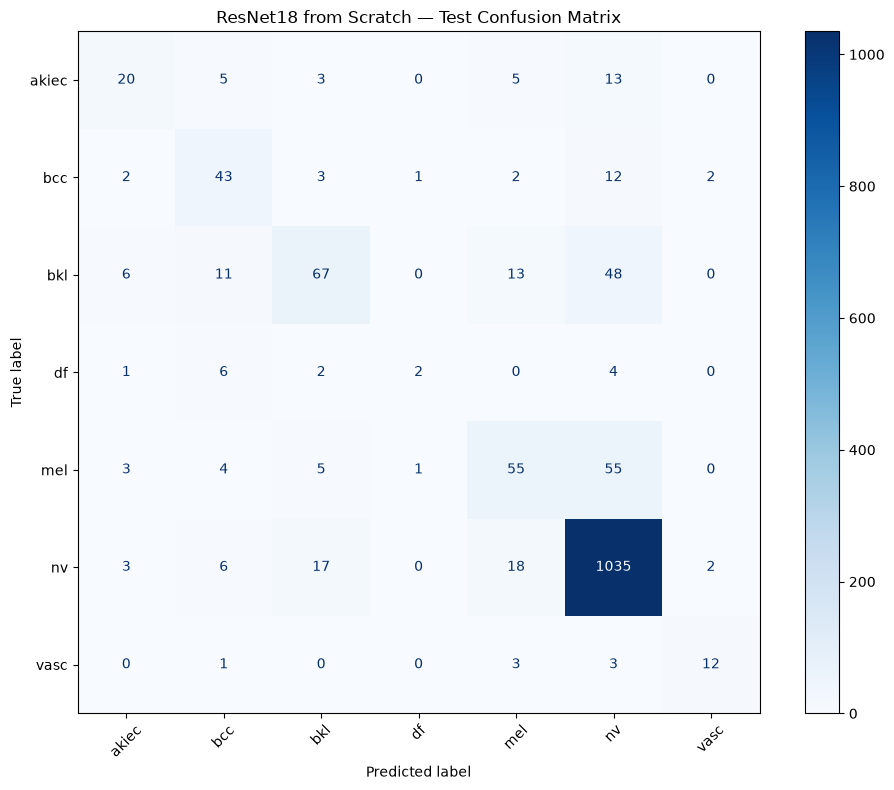

In [34]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import torch

# Load the best validation checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Best validation macro-F1:", checkpoint["best_val_f1"])

# Collect predictions on the test set
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate overall metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"\nTest accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

# Per-class report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=[idx_to_class[i] for i in range(NUM_CLASSES)],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[idx_to_class[i] for i in range(NUM_CLASSES)]
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)
plt.title("ResNet18 from Scratch — Test Confusion Matrix")
plt.tight_layout()
plt.show()